In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import root_mean_squared_error
from statsmodels.tsa.api import ExponentialSmoothing
from statsmodels.tsa.api import Holt
from statsmodels.tsa.api import SimpleExpSmoothing
from tqdm import  tqdm
import warnings
warnings.filterwarnings('ignore')
import os
os.chdir('E:/Machine_Learning/Datasets/')

In [2]:
df = pd.read_csv('BUNDESBANK-BBK01_WT5511.csv')
df.head()

,Date,Value
0,30-04-1968,39.10
1,31-05-1968,42.00
2,30-06-1968,40.95
3,31-07-1968,38.90
4,31-08-1968,39.85


In [4]:
y = df['Value']
y_train,y_test = y.iloc[:-12],y.iloc[-12:]
y_train.shape,y_test.shape

((565,), (12,))

In [5]:
alpha = np.linspace(0.01,0.99,10)
beta = np.linspace(0.01,0.99,10)

scores = []

for a in tqdm(alpha):
    for b in beta:
        for e in [True,False]:
            holt  = Holt(y_train, initialization_method='estimated',exponential=e) 
            fit1 = holt.fit(smoothing_level=a,smoothing_trend=b)
            fcast1 = fit1.forecast(len(y_test))
            scores.append([a,b,e,root_mean_squared_error(y_test,fcast1)])

df_scores = pd.DataFrame(scores,columns=['alpha','beta','Exponential','score'])
df_scores.sort_values('score',ascending=True)



100%|██████████| 10/10 [00:05<00:00,  1.91it/s]


,alpha,beta,Exponential,score
53,0.227778,0.663333,False,65.267790
52,0.227778,0.663333,True,66.187505
1,0.010000,0.010000,False,66.527513
24,0.118889,0.227778,True,68.712766
25,0.118889,0.227778,False,70.084986
...,...,...,...,...
5,0.010000,0.227778,False,572.618824
17,0.010000,0.881111,False,615.125790
19,0.010000,0.990000,False,764.732536
3,0.010000,0.118889,False,874.703994


In [7]:
alpha = np.linspace(0.01,0.99,20)
beta = np.linspace(0.01,0.99,20)
gamma = np.linspace(0.01,0.99,20)
scores = []

for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
            for s in ['add','mul']:
                hw_add = ExponentialSmoothing(y_train,seasonal_periods=12,trend = 'add',seasonal = s)
                fit1 = hw_add.fit(smoothing_level = a ,smoothing_trend = b ,smoothing_seasonal = g)
                fcast1 = fit1.forecast(len(y_test))
                scores.append([s,a,b,g,root_mean_squared_error(y_test,fcast1)])

df_scores = pd.DataFrame(scores,columns=['seasonality','alpha','beta','gamma','score'])
df_scores.sort_values('score',ascending=True)

100%|██████████| 20/20 [27:41<00:00, 83.08s/it] 


,seasonality,alpha,beta,gamma,score
4035,mul,0.267895,0.010000,0.886842,5.598121e+01
3234,add,0.216316,0.010000,0.886842,5.636314e+01
4037,mul,0.267895,0.010000,0.938421,5.656481e+01
3232,add,0.216316,0.010000,0.835263,5.662087e+01
4033,mul,0.267895,0.010000,0.835263,5.739978e+01
...,...,...,...,...,...
15956,add,0.990000,0.938421,0.938421,8.165689e+11
15918,add,0.990000,0.886842,0.990000,3.167569e+12
15996,add,0.990000,0.990000,0.938421,6.420031e+13
15958,add,0.990000,0.938421,0.990000,1.419184e+14


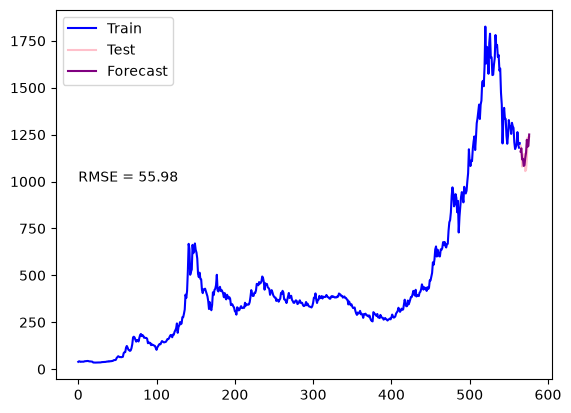

In [9]:
hw_add = ExponentialSmoothing(y_train,seasonal_periods=12,trend = 'add',seasonal = 'mul')
fit1 = hw_add.fit(smoothing_level =0.267895 ,smoothing_trend = 0.01 ,smoothing_seasonal = 0.886842)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color='blue',label = 'Train')
y_test.plot(color='pink',label = 'Test')
fcast1.plot(color = 'Purple',label = 'Forecast')
rms = np.round(root_mean_squared_error(y_test,fcast1),2)
plt.text(00,1000, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()
